# 0. Imports and Data Loading

In [ ]:
#required for first time install in environment
#!pip install xgboost
#!pip install shap

In [1]:
#imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import random

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, TargetEncoder, LabelBinarizer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, roc_curve, auc, precision_recall_curve, average_precision_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from itertools import cycle

from xgboost import XGBClassifier

In [2]:
#Loading the dataset
triage_df = pd.read_parquet('Data/processed_triage_dataset.parquet')

#Loading the LLM synthetic ESI 1 records
LLM_synthetics_df = pd.read_csv('Data/LLM Synthetic Experiment/LLM Output MASTER.csv')

#Splitting main dataset into train test and eval sets
#Maintaining the same splits used in all experiments
#Val splits are not needed at this point, but included to ensure that train and test splits are maintained across experiments

X = triage_df.drop(columns='esi')
y = triage_df['esi']

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)

X_train, X_val, y_train, y_val =  train_test_split(
    X_train_val, y_train_val, test_size=0.176, stratify=y_train_val, random_state=42
)

#splitting LLM-Synthetic set and concatenating with baseline dataset
X1 = LLM_synthetics_df.drop(columns='esi')
y1 = LLM_synthetics_df['esi']

X_train = pd.concat([X_train, X1])
y_train = pd.concat([y_train, y1])

#ensure y_train esi datatype is str
#prevents issues with LLM samples being int and baseline being str
y_train = y_train.astype(str)

#Encoding target
#replacing ESI 1-5 with int 0-4
le = LabelEncoder()
le.fit(y_train)

y_train_encoded = le.transform(y_train)
y_test_encoded = le.transform(y_test)

In [3]:
#labels used in evaluation visuals
esi_labels = ['1', '2', '3', '4', '5']

## Plotting Functions:

In [4]:
#Function for plotting ROC-AUC curve for single model
#Takes as inputs:
#modelName a string to be used in the plot title e.g. "XGBoost V1"
#y_test which is the y_true values to check against e.g. y_val_encoded
#y_score which is the models predicted y value probas e.g. my_pred_probas
#Returns:
#A plot showing ROC curves for each ESI class and a macro-avg curve


def PlotROC_oneModel(modelName, y_test, y_score):

    #Assign ESI code to each class value
    class_names = { 
        0:"ESI 1",
        1:"ESI 2",
        2:"ESI 3",
        3:"ESI 4",
        4:"ESI 5"
    }
    #One-hot encode y_test
    y_onehot_test = label_binarizer.transform(y_test)

    #calculate individual ROC curves for each of the 5 ESI levels
    fpr, tpr, roc_auc = dict(), dict(), dict()
    for i in range(5):
        fpr[i], tpr[i], _ = roc_curve(y_onehot_test[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    #calculate Macro-avg ROC-AUC
    fpr_grid = np.linspace(0.0,1.0,1000)
    mean_tpr = np.zeros_like(fpr_grid)

    for i in range(5):
        mean_tpr += np.interp(fpr_grid, fpr[i], tpr[i])

    #Average it and Compute AUC
    mean_tpr /= 5
    fpr['macro'] = fpr_grid
    tpr['macro'] = mean_tpr
    roc_auc['macro'] = auc(fpr['macro'], tpr['macro'])

    #Plotting
    fig, ax = plt.subplots(figsize = (8,8))

    #plotting the avg curve
    plt.plot(
        fpr['macro'],
        tpr['macro'],
        label = f"Macro-Avg (AUC = {roc_auc['macro']:.2f})",
        color = 'black',
        linestyle = '--',
        linewidth = 2
    )

    #Plotting each ESI score curve
    colors = cycle(['lightblue','darkorange','navy','brown','green'])
    for class_id, color in zip(range(5), colors):
        RocCurveDisplay.from_predictions(
            y_onehot_test[:, class_id],
            y_score[:, class_id],
            name = class_names[class_id],
            ax = ax,
            plot_chance_level = (class_id == 4), #4 for final class, put it last in legend
            despine = True,
            color = color
        )
    #Formatting Titles and Labels:
    _ = ax.set(
        xlabel="False Positive Rate",
        ylabel="True Positive Rate",
        title =f"ROC Curve for {modelName} (One-vs-Rest)"
    )
    plt.legend(loc='lower right')
    plt.show()

In [5]:
#Function for plotting Precision Recall curve for single model
#Takes as inputs:
#modelName a string to be used in the plot title e.g. "XGBoost V1"
#y_test which is the y_true values to check against e.g. y_val_encoded
#y_score which is the models predicted y value probas e.g. my_pred_probas
#Returns:
#A plot showing PRecision Recall curves for each ESI class and a macro-avg curve

def PlotPR_oneModel(modelName, y_test, y_score):

     #Assign ESI code to each class value
    class_names = { 
        0:"ESI 1",
        1:"ESI 2",
        2:"ESI 3",
        3:"ESI 4",
        4:"ESI 5"
    }
    #One-hot encode y_test
    y_onehot_test = label_binarizer.transform(y_test)

    #Calculate individual PR curves for each of the 5 ESI levels
    precision, recall, average_precision = dict(), dict(), dict()
    for i in range(5):
        precision[i], recall[i], _ = precision_recall_curve(y_onehot_test[:, i], y_score[:, i])
        average_precision[i] = average_precision_score(y_onehot_test[:, i], y_score[:, i])

    #Calculate Macro-avg PR
    recall_grid = np.linspace(0.0, 1.0, 1000)
    mean_precision = np.zeros_like(recall_grid)

    for i in range(5):
        mean_precision += np.interp(recall_grid,recall[i][::-1], precision[i][::-1])
        #reverse the arrays [::-1] to give ascending X-values to np.interp

    #average it and compute PR
    mean_precision /= 5
    recall['macro'] = recall_grid
    precision['macro'] = mean_precision
    average_precision['macro'] = average_precision_score(y_onehot_test, y_score, average='macro')

    #plotting
    fig, ax = plt.subplots(figsize = (8,8))

    #plotting the avg curve
    display = PrecisionRecallDisplay(
        recall=recall['macro'],
        precision=precision['macro'],
        average_precision=average_precision['macro']
    )
    display.plot(
        ax= ax, 
        name="Macro-Avg Precision-Recall", 
        color = "black"
    )

    #Plotting each ESI score curve
    colors = cycle(['lightblue','darkorange','navy','brown','green'])
    for class_id, color in zip(range(5), colors):
        display = PrecisionRecallDisplay(
            recall=recall[class_id],
            precision=precision[class_id],
            average_precision=average_precision[class_id]
        )
        display.plot(
            ax=ax,
            name=f"Precision-Recall for {class_names[class_id]}",
            color = color,
            despine = True
        )
    #set the legend, title and axes:
    handles,labels = display.ax_.get_legend_handles_labels()
    ax.legend(handles=handles, labels=labels, loc='upper right')
    ax.set_title(f"Precision-Recall Curve for {modelName}")

    plt.show()


## Target Encoding chief_complaint

In [6]:
#instantiate the encoder
#uses cross-fold validation inbuilt

encoder = TargetEncoder(target_type='continuous', smooth='auto', cv= 5, random_state=42)
#countinuous used despite being a categorical due to ordinal nature of esi 

X_train_encoded = X_train.copy()
X_test_encoded = X_test.copy()

#Fit and transform on Training data
#learning the relationship between chief_complaint and target feature
X_train_encoded['chief_complaint'] = encoder.fit_transform(X_train[['chief_complaint']],y_train_encoded)

#Transform only for  test data
#blindly applies the mappings from training data to transform the val/test data
X_test_encoded['chief_complaint'] = encoder.transform(X_test[['chief_complaint']])



In [7]:
#Creating a lookup dictionary
#pairing unique chief complaint to the encoded float value
#Useful to decode the values back to text

#extracting the unique original chief complaints and encodings for them
unique_complaints = X_train[['chief_complaint']].drop_duplicates()
encoded_floats = encoder.transform(unique_complaints)
#flatten to 1D array
encoded_floats_flat = encoded_floats.flatten()

#building the dictionary
#rounding all encodings to 5 decimals
cc_mapping = {}
for original_string, enc_float in zip(unique_complaints['chief_complaint'], encoded_floats_flat):
    val =  enc_float #enc_float[0] if isinstance(enc_float, np.ndarray) else

    rounded_key = round(val, 5)
    cc_mapping[rounded_key] = original_string

# 1. Training Model

In [8]:
#Model training follows similar steps to tune_XGBoost function
#using a pipeline to apply SMOTE before fitting
#The model's Hyperparameters are based on the LLM-Boosted experiment's best results

smote = SMOTE(
    sampling_strategy={0: 5000, 4: 20000},
    random_state=42
)
xGBoost = XGBClassifier(
    n_estimators = 2781,
    learning_rate = 0.02,
    max_depth = 7,
    min_child_weight = 4,
    subsample = 0.9,
    colsample_bytree = 0.6,
    reg_alpha = 2,
    reg_lambda = 7
)

final_model = ImbPipeline([
    ('oversample', smote),
    ('xgb', xGBoost)
])

#fitting the model
final_model.fit(X_train_encoded,y_train_encoded)

Pipeline(steps=[('oversample',
                 SMOTE(random_state=42, sampling_strategy={0: 5000, 4: 20000})),
                ('xgb',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=0.6, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric=None,
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.02,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=7, max_leaves=None, min_child_weight=4,
                               missing=nan, monotone_constraints=None,
                               multi_strategy=None, n_estimators=2781,
                               n_jobs=None, num_parallel_tree=None, ...))])

In [9]:
#Defining threshold weights
#values taken from final model in experiments
weights = [26.74, 1, 1, 1, 2.98]

# 2. Predicting on Test set

In [10]:
#Baseline predictions
base_preds = final_model.predict_proba(X_test_encoded)

#Applying threshold weights
optimized_preds = base_preds * weights

#reversing label encoding
final_preds = le.inverse_transform(np.argmax(optimized_preds, axis = 1))

## Evaluation

In [11]:
#declaring label binarizer for plotting functions
label_binarizer = LabelBinarizer().fit(y_train_encoded)

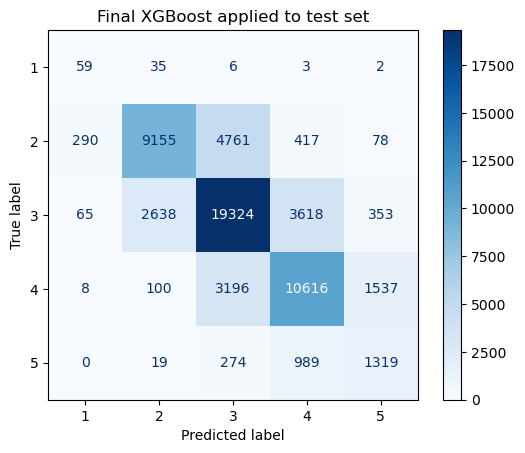

Classification Report:
               precision    recall  f1-score   support

           1       0.14      0.56      0.22       105
           2       0.77      0.62      0.69     14701
           3       0.70      0.74      0.72     25998
           4       0.68      0.69      0.68     15457
           5       0.40      0.51      0.45      2601

    accuracy                           0.69     58862
   macro avg       0.54      0.62      0.55     58862
weighted avg       0.70      0.69      0.69     58862



In [12]:
cm = confusion_matrix(y_test,final_preds, labels=esi_labels)
disp = ConfusionMatrixDisplay(cm, display_labels=esi_labels)
disp.plot(cmap="Blues")
plt.title("Final XGBoost applied to test set")
plt.show()

print("Classification Report:\n", classification_report(y_test,final_preds))

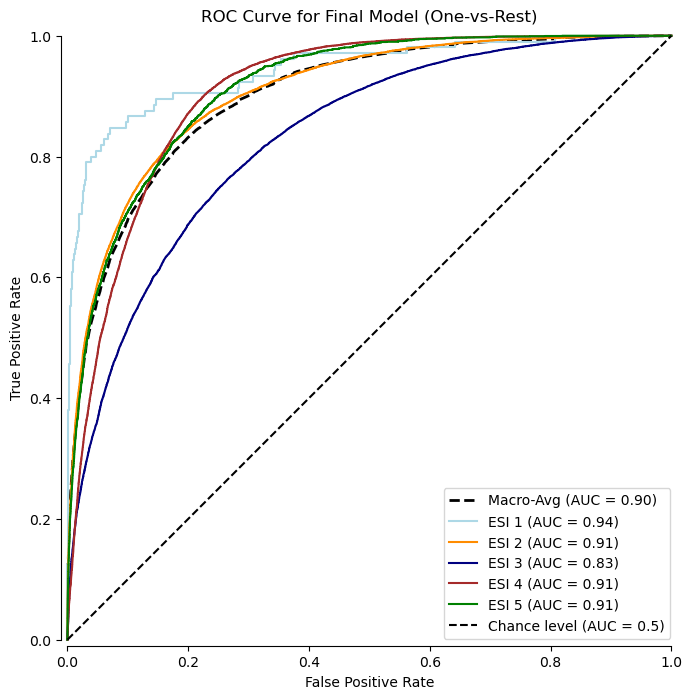

In [37]:
PlotROC_oneModel(
    modelName = 'Final Model',
    y_test = y_test_encoded,
    y_score = optimized_preds
)

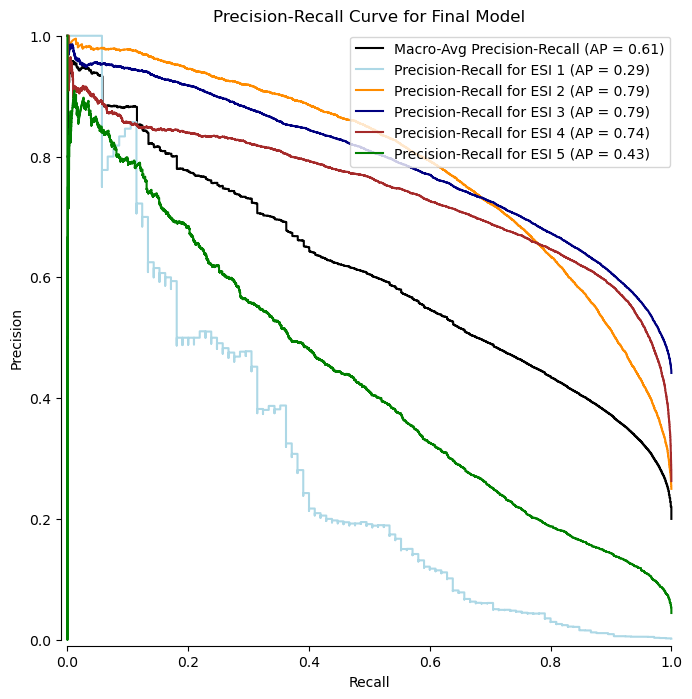

In [38]:
PlotPR_oneModel(
    modelName = 'Final Model',
    y_test = y_test_encoded,
    y_score = optimized_preds
)

# 3. Decision Support System - Proof of Concept

## Decision support system Function

In [ ]:
#This function takes 1 patient record as input
#Applies the model to it, to predict the patients ESI score
#finds the top SHAP explainations 
#then outputs the predicted score, confidence score and contributing factors

def predictTriageScore(patient_data, model = final_model, final_weights = weights, cc_mapping = cc_mapping):

    #initialize SHAP explainer
    explainer = shap.TreeExplainer(model.named_steps['xgb'])

    #creating list of pmh_cols
    pmh_cols = patient_data.filter(like="pmh_")

    #predict model on patient_data and apply weights
    raw_probs = model.predict_proba(patient_data)
    weighted_probs = raw_probs * final_weights

    #identify winning class and calulate confidence score
    predicted_class_encoded = np.argmax(weighted_probs)
    confidence_score = raw_probs[0, predicted_class_encoded] * 100
    #convert encoded ESI to true ESI code
    predicted_esi = predicted_class_encoded + 1

    #SHAP explainations for top contributors to ESI score
    #Limiting explainations to only the predicted class
    #sorted by impact to return the top 5 contributors
    
    shap_values = explainer.shap_values(patient_data)
    predicted_class_shap = shap_values[0, :, predicted_class_encoded]

    #sorting by absolute impact and limiting to 5
    top_indices = np.argsort(np.abs(predicted_class_shap))[::-1][:5]
    feature_names = patient_data.columns

    #Outputting Predicted ESI score, confidence Score and top 5 factors

    print(f"Recommended ESI score for patient: ESI {predicted_esi}")
    print(f"Confidence Score: {confidence_score:.1f}%\n")
    print("---- Top 5 factors contributing to recommended ESI score ----\n")

    #outputting contributing factors
    #formatting feature names and values
    
    for i, idx in enumerate(top_indices):
        feature = feature_names[idx]
        raw_val = patient_data.iloc[0, idx]

        #formatting chief complaint
        #swapping target encoded chief complaint back to text
        if feature == 'chief_complaint':
            feature = "Chief Complaint"
            #round value to 5 dec places to match dictionary keys
            rounded_raw_val = round(float(raw_val), 5)
            display_val = f"{cc_mapping.get(rounded_raw_val, )}"

        #formatting gender
        #replacing encoded gender with text
        elif feature == 'gender':
            feature = 'Gender'
            if raw_val == 0:
                display_val = "Male"
            else:
                display_val = "Female"

        #fromatting PMH cols
        #removing pmh_ prefix from feature name
        #replacing PMH col "1" as "Previous History"
        elif feature in pmh_cols:
            display_val = feature.removeprefix("pmh_")
            if raw_val == 1:
                feature = "Previous history of"
        
        #Formatting arrival mode
        elif feature == 'arrivalmode_unassisted':
            feature = "Unassisted Arrival"
            if raw_val == 1.0:
                display_val = "True"
            else:
                display_val = "False"
        elif feature == 'arrivalmode_emergencyservices':
            feature = "Emergency Services Arrival"
            if raw_val == 1.0:
                display_val = "True"
            else:
                display_val = "False"
        elif feature == 'arrivalmode_Wheelchair':
            feature = "Wheelchair Arrival"
            if raw_val == 1:
                display_val = "True"
            else:
                display_val = "False"

        #formatting Previous Dispo
        elif feature == 'previousdispo_Admit':
            feature = "Previously Admitted"
            if raw_val == 1:
                display_val = "True"
            else:
                display_val = "False"
        elif feature == 'previousdispo_Discharge':
            feature = "Previously Discharged"
            if raw_val == 1:
                display_val = "True"
            else:
                display_val = "False"
        elif feature == 'previousdispo_No previous dispo':
            feature = "No Previous Disposition"
            if raw_val == 1:
                display_val = "True"
            else:
                display_val = "False"

        #formatting meds tier
        elif feature == 'meds_tier1':
            feature = "Tier 1 Meds Count"
            display_val = raw_val
        elif feature == 'meds_tier2':
            feature = "Tier 2 Meds Count"
            display_val = raw_val
        elif feature == 'meds_tier3':
            feature = "Tier 3 Meds Count"
            display_val = raw_val
        elif feature == 'meds_tier4':
            feature = "Tier 4 Meds Count"
            display_val = raw_val

        #formatting triage vitals
        elif feature =='triage_vital_o2_device':
            feature = "Supplementary o2 device"
            if raw_val == 1:
                display_val = "True"
            else:
                display_val = "False"
        elif feature == 'triage_vital_hr':
            feature = 'Heart Rate'
            display_val = round(float(raw_val), 2)
        elif feature == 'triage_vital_sbp':
            feature = 'Systolic Blood Pressure'
            display_val = round(float(raw_val), 2)
        elif feature == 'triage_vital_dbp':
            feature = 'Diasystolic Blood Pressure'
            display_val = round(float(raw_val), 2)
        elif feature == 'triage_vital_rr':
            feature = 'Respiratory Rate'
            display_val = round(float(raw_val), 2)
        elif feature == 'triage_vital_o2':
            feature = 'o2 Desaturation'
            display_val = round(float(raw_val), 2)
        elif feature == 'triage_vital_temp':
            feature = 'Core Temperature'
            display_val = round(float(raw_val), 2)

        #Formatting n_admissions, n_edvisits, n_sugeries
        elif feature == 'n_admissions':
            feature = 'No. Previous Hospital Admissions'
            display_val = raw_val
        elif feature == 'n_edvisits':
            feature = 'No. Previous ED Visits'
            display_val = raw_val
        elif feature == 'n_sugeries':
            feature = 'No. Previous Surgeries'
            display_val = raw_val

        #otherwise keep the default feature name and display value
        else:
            feature = feature.capitalize()
            display_val = raw_val
        
        print(f"{i+1}. {feature}: {display_val}")

## Applying function to test patients

In [11]:
#Finding the total number of samples within the test set
X_test_encoded.shape

(58862, 304)

In [27]:
#allowing pandas to output all cols
pd.options.display.max_columns = 400

### Patient 1

In [244]:
#select a patient at random from the test set
patient_no = random.randint(0,58861)

#Patient no. passed to iloc as a list
#avoids an error where the row index is passed to the pipeline and included as a feature
patient_record = X_test_encoded.iloc[[patient_no]]
patient_true_esi = y_test.iloc[[patient_no]]

#Predicting the triage score for patient
predictTriageScore(patient_record)

Recommended ESI score for patient: ESI 1
Confidence Score: 11.5%

---- Top 5 factors contributing to recommended ESI score ----

1. Respiratory Rate: 14.0
2. Heart Rate: 114.0
3. Unassisted Arrival: False
4. Diasystolic Blood Pressure: 92.0
5. Chief Complaint: other


In [245]:
#Checking patient True ESI  
print(patient_true_esi)

20144    2
Name: esi, dtype: category
Categories (5, object): ['1', '2', '3', '4', '5']


In [246]:
#displaying patient record to be used in testing documentation
patient_record

,age,gender,pmh_2ndarymalig,pmh_abdomhernia,pmh_abdomnlpain,pmh_abortcompl,pmh_acqfootdef,pmh_acrenlfail,pmh_acutecvd,pmh_acutemi,pmh_acutphanm,pmh_adjustmentdisorders,pmh_adltrespfl,pmh_alcoholrelateddisorders,pmh_allergy,pmh_amniosdx,pmh_analrectal,pmh_anemia,pmh_aneurysm,pmh_anxietydisorders,pmh_appendicitis,pmh_artembolism,pmh_asppneumon,pmh_asthma,pmh_attentiondeficitconductdisruptivebeha,pmh_backproblem,pmh_biliarydx,pmh_birthasphyx,pmh_birthtrauma,pmh_bladdercncr,pmh_blindness,pmh_bnignutneo,pmh_bonectcncr,pmh_bph,pmh_brainnscan,pmh_breastcancr,pmh_breastdx,pmh_brnchlngca,pmh_bronchitis,pmh_burns,pmh_cardiaarrst,pmh_cardiacanom,pmh_carditis,pmh_cataract,pmh_cervixcancr,pmh_chestpain,pmh_chfnonhp,pmh_chrkidneydisease,pmh_coaghemrdx,pmh_coloncancer,pmh_comabrndmg,pmh_complicdevi,pmh_complicproc,pmh_conduction,pmh_contraceptiv,pmh_copd,pmh_coronathero,pmh_crushinjury,pmh_cysticfibro,pmh_deliriumdementiaamnesticothercognitiv,pmh_developmentaldisorders,pmh_diabmelnoc,pmh_diabmelwcm,pmh_disordersusuallydiagnosedininfancych,pmh_diverticulos,pmh_dizziness,pmh_dminpreg,pmh_dysrhythmia,pmh_earlylabor,pmh_ecodesadverseeffectsofmedicalcare,pmh_ecodesadverseeffectsofmedicaldrugs,pmh_ecodescutpierce,pmh_ecodesdrowningsubmersion,pmh_ecodesfall,pmh_ecodesfirearm,pmh_ecodesfireburn,pmh_ecodesmachinery,pmh_ecodesmotorvehicletrafficmvt,pmh_ecodesnaturalenvironment,pmh_ecodesotherspecifiedandclassifiable,pmh_ecodesotherspecifiednec,pmh_ecodespedalcyclistnotmvt,pmh_ecodesplaceofoccurrence,pmh_ecodespoisoning,pmh_ecodesstruckbyagainst,pmh_ecodessuffocation,pmh_ecodestransportnotmvt,pmh_ecodesunspecified,pmh_ectopicpreg,pmh_encephalitis,pmh_endometrios,pmh_epilepsycnv,pmh_esophcancer,pmh_esophgealdx,pmh_exameval,pmh_eyeinfectn,pmh_fatigue,pmh_femgenitca,pmh_feminfertil,pmh_fetaldistrs,pmh_fluidelcdx,pmh_fuo,pmh_fxarm,pmh_fxhip,pmh_fxleg,pmh_fxskullfac,pmh_gangrene,pmh_gasduoulcer,pmh_gastritis,pmh_gastroent,pmh_giconganom,pmh_gihemorrhag,pmh_giperitcan,pmh_glaucoma,pmh_goutotcrys,pmh_guconganom,pmh_hdnckcancr,pmh_headachemig,pmh_hemmorhoids,pmh_hemorrpreg,pmh_hepatitis,pmh_hivinfectn,pmh_hodgkinsds,pmh_hrtvalvedx,pmh_htn,pmh_htncomplicn,pmh_htninpreg,pmh_hyperlipidem,pmh_immunitydx,pmh_immunizscrn,pmh_impulsecontroldisordersnec,pmh_inducabortn,pmh_infectarth,pmh_influenza,pmh_infmalegen,pmh_intestinfct,pmh_intobstruct,pmh_intracrninj,pmh_jointinjury,pmh_kidnyrnlca,pmh_lateeffcvd,pmh_leukemias,pmh_liveborn,pmh_liveribdca,pmh_longpregncy,pmh_lowbirthwt,pmh_lungexternl,pmh_lymphenlarg,pmh_maintchemr,pmh_malgenitca,pmh_maligneopls,pmh_malposition,pmh_meningitis,pmh_menopausldx,pmh_menstrualdx,pmh_miscellaneousmentalhealthdisorders,pmh_mooddisorders,pmh_mouthdx,pmh_ms,pmh_multmyeloma,pmh_mycoses,pmh_nauseavomit,pmh_neoplsmunsp,pmh_nephritis,pmh_nervcongan,pmh_nonepithca,pmh_nonhodglym,pmh_nutritdefic,pmh_obrelatedperintrauma,pmh_opnwndextr,pmh_opnwndhead,pmh_osteoarthros,pmh_osteoporosis,pmh_otacqdefor,pmh_otaftercare,pmh_otbnignneo,pmh_otbonedx,pmh_otcirculdx,pmh_otcomplbir,pmh_otconganom,pmh_otconntiss,pmh_otdxbladdr,pmh_otdxkidney,pmh_otdxstomch,pmh_otendodsor,pmh_otfemalgen,pmh_othbactinf,pmh_othcnsinfx,pmh_othematldx,pmh_othercvd,pmh_othereardx,pmh_otheredcns,pmh_othereyedx,pmh_othergidx,pmh_othergudx,pmh_otherinjury,pmh_otherpregnancyanddeliveryincludingnormal,pmh_otherscreen,pmh_othfracture,pmh_othheartdx,pmh_othinfectns,pmh_othliverdx,pmh_othlowresp,pmh_othmalegen,pmh_othnervdx,pmh_othskindx,pmh_othveindx,pmh_otinflskin,pmh_otitismedia,pmh_otjointdx,pmh_otnutritdx,pmh_otperintdx,pmh_otpregcomp,pmh_otprimryca,pmh_otrespirca,pmh_otupprresp,pmh_otuprspin,pmh_ovariancyst,pmh_ovarycancer,pmh_pancreascan,pmh_pancreasdx,pmh_paralysis,pmh_parkinsons,pmh_pathologfx,pmh_pelvicobstr,pmh_perintjaund,pmh_peripathero,pmh_peritonitis,pmh_personalitydisorders,pmh_phlebitis,pmh_pid,pmh_pleurisy,pmh_pneumonia,pmh_poisnnonmed,pmh_poisnotmed,pmh_poisonpsych,pmh_precereoccl,pmh_prevcsectn,pmh_prolapse,pmh_prostatecan,pmh_pulmhartdx,pmh_rctmanusca,pmh_rehab,pmh

### Patient 2

In [217]:
#select a patient at random from the test set
patient_no = random.randint(0,58861)

#Patient no. passed to iloc as a list
#avoids an error where the row index is passed to the pipeline and included as a feature
patient_record = X_test_encoded.iloc[[patient_no]]
patient_true_esi = y_test.iloc[[patient_no]]

#Predicting the triage score for patient
predictTriageScore(patient_record)

Recommended ESI score for patient: ESI 2
Confidence Score: 53.0%

---- Top 5 factors contributing to recommended ESI score ----

1. o2 Desaturation: 90.0
2. Chief Complaint: legswelling
3. No. Previous Hospital Admissions: 4
4. Previously Admitted: True
5. Tier 1 Meds Count: 1.0


In [218]:
#Checking patient True ESI  
print(patient_true_esi)

195710    2
Name: esi, dtype: category
Categories (5, object): ['1', '2', '3', '4', '5']


In [219]:
#displaying patient record to be used in testing documentation
patient_record

,age,gender,pmh_2ndarymalig,pmh_abdomhernia,pmh_abdomnlpain,pmh_abortcompl,pmh_acqfootdef,pmh_acrenlfail,pmh_acutecvd,pmh_acutemi,pmh_acutphanm,pmh_adjustmentdisorders,pmh_adltrespfl,pmh_alcoholrelateddisorders,pmh_allergy,pmh_amniosdx,pmh_analrectal,pmh_anemia,pmh_aneurysm,pmh_anxietydisorders,pmh_appendicitis,pmh_artembolism,pmh_asppneumon,pmh_asthma,pmh_attentiondeficitconductdisruptivebeha,pmh_backproblem,pmh_biliarydx,pmh_birthasphyx,pmh_birthtrauma,pmh_bladdercncr,pmh_blindness,pmh_bnignutneo,pmh_bonectcncr,pmh_bph,pmh_brainnscan,pmh_breastcancr,pmh_breastdx,pmh_brnchlngca,pmh_bronchitis,pmh_burns,pmh_cardiaarrst,pmh_cardiacanom,pmh_carditis,pmh_cataract,pmh_cervixcancr,pmh_chestpain,pmh_chfnonhp,pmh_chrkidneydisease,pmh_coaghemrdx,pmh_coloncancer,pmh_comabrndmg,pmh_complicdevi,pmh_complicproc,pmh_conduction,pmh_contraceptiv,pmh_copd,pmh_coronathero,pmh_crushinjury,pmh_cysticfibro,pmh_deliriumdementiaamnesticothercognitiv,pmh_developmentaldisorders,pmh_diabmelnoc,pmh_diabmelwcm,pmh_disordersusuallydiagnosedininfancych,pmh_diverticulos,pmh_dizziness,pmh_dminpreg,pmh_dysrhythmia,pmh_earlylabor,pmh_ecodesadverseeffectsofmedicalcare,pmh_ecodesadverseeffectsofmedicaldrugs,pmh_ecodescutpierce,pmh_ecodesdrowningsubmersion,pmh_ecodesfall,pmh_ecodesfirearm,pmh_ecodesfireburn,pmh_ecodesmachinery,pmh_ecodesmotorvehicletrafficmvt,pmh_ecodesnaturalenvironment,pmh_ecodesotherspecifiedandclassifiable,pmh_ecodesotherspecifiednec,pmh_ecodespedalcyclistnotmvt,pmh_ecodesplaceofoccurrence,pmh_ecodespoisoning,pmh_ecodesstruckbyagainst,pmh_ecodessuffocation,pmh_ecodestransportnotmvt,pmh_ecodesunspecified,pmh_ectopicpreg,pmh_encephalitis,pmh_endometrios,pmh_epilepsycnv,pmh_esophcancer,pmh_esophgealdx,pmh_exameval,pmh_eyeinfectn,pmh_fatigue,pmh_femgenitca,pmh_feminfertil,pmh_fetaldistrs,pmh_fluidelcdx,pmh_fuo,pmh_fxarm,pmh_fxhip,pmh_fxleg,pmh_fxskullfac,pmh_gangrene,pmh_gasduoulcer,pmh_gastritis,pmh_gastroent,pmh_giconganom,pmh_gihemorrhag,pmh_giperitcan,pmh_glaucoma,pmh_goutotcrys,pmh_guconganom,pmh_hdnckcancr,pmh_headachemig,pmh_hemmorhoids,pmh_hemorrpreg,pmh_hepatitis,pmh_hivinfectn,pmh_hodgkinsds,pmh_hrtvalvedx,pmh_htn,pmh_htncomplicn,pmh_htninpreg,pmh_hyperlipidem,pmh_immunitydx,pmh_immunizscrn,pmh_impulsecontroldisordersnec,pmh_inducabortn,pmh_infectarth,pmh_influenza,pmh_infmalegen,pmh_intestinfct,pmh_intobstruct,pmh_intracrninj,pmh_jointinjury,pmh_kidnyrnlca,pmh_lateeffcvd,pmh_leukemias,pmh_liveborn,pmh_liveribdca,pmh_longpregncy,pmh_lowbirthwt,pmh_lungexternl,pmh_lymphenlarg,pmh_maintchemr,pmh_malgenitca,pmh_maligneopls,pmh_malposition,pmh_meningitis,pmh_menopausldx,pmh_menstrualdx,pmh_miscellaneousmentalhealthdisorders,pmh_mooddisorders,pmh_mouthdx,pmh_ms,pmh_multmyeloma,pmh_mycoses,pmh_nauseavomit,pmh_neoplsmunsp,pmh_nephritis,pmh_nervcongan,pmh_nonepithca,pmh_nonhodglym,pmh_nutritdefic,pmh_obrelatedperintrauma,pmh_opnwndextr,pmh_opnwndhead,pmh_osteoarthros,pmh_osteoporosis,pmh_otacqdefor,pmh_otaftercare,pmh_otbnignneo,pmh_otbonedx,pmh_otcirculdx,pmh_otcomplbir,pmh_otconganom,pmh_otconntiss,pmh_otdxbladdr,pmh_otdxkidney,pmh_otdxstomch,pmh_otendodsor,pmh_otfemalgen,pmh_othbactinf,pmh_othcnsinfx,pmh_othematldx,pmh_othercvd,pmh_othereardx,pmh_otheredcns,pmh_othereyedx,pmh_othergidx,pmh_othergudx,pmh_otherinjury,pmh_otherpregnancyanddeliveryincludingnormal,pmh_otherscreen,pmh_othfracture,pmh_othheartdx,pmh_othinfectns,pmh_othliverdx,pmh_othlowresp,pmh_othmalegen,pmh_othnervdx,pmh_othskindx,pmh_othveindx,pmh_otinflskin,pmh_otitismedia,pmh_otjointdx,pmh_otnutritdx,pmh_otperintdx,pmh_otpregcomp,pmh_otprimryca,pmh_otrespirca,pmh_otupprresp,pmh_otuprspin,pmh_ovariancyst,pmh_ovarycancer,pmh_pancreascan,pmh_pancreasdx,pmh_paralysis,pmh_parkinsons,pmh_pathologfx,pmh_pelvicobstr,pmh_perintjaund,pmh_peripathero,pmh_peritonitis,pmh_personalitydisorders,pmh_phlebitis,pmh_pid,pmh_pleurisy,pmh_pneumonia,pmh_poisnnonmed,pmh_poisnotmed,pmh_poisonpsych,pmh_precereoccl,pmh_prevcsectn,pmh_prolapse,pmh_prostatecan,pmh_pulmhartdx,pmh_rctmanusca,pmh_rehab,pmh

### Patient 3

In [281]:
#select a patient at random from the test set
patient_no = random.randint(0,58861)


#Patient no. passed to iloc as a list
#avoids an error where the row index is passed to the pipeline and included as a feature
patient_record = X_test_encoded.iloc[[patient_no]]
patient_true_esi = y_test.iloc[[patient_no]]

#Predicting the triage score for patient
predictTriageScore(patient_record)

Recommended ESI score for patient: ESI 1
Confidence Score: 8.7%

---- Top 5 factors contributing to recommended ESI score ----

1. Systolic Blood Pressure: 79.0
2. Diasystolic Blood Pressure: 41.0
3. Heart Rate: 134.0
4. Respiratory Rate: 18.0
5. Previous history of: htn


In [282]:
#Checking patient True ESI  
print(patient_true_esi)

354175    2
Name: esi, dtype: category
Categories (5, object): ['1', '2', '3', '4', '5']


In [283]:
#displaying patient record to be used in testing documentation
patient_record

,age,gender,pmh_2ndarymalig,pmh_abdomhernia,pmh_abdomnlpain,pmh_abortcompl,pmh_acqfootdef,pmh_acrenlfail,pmh_acutecvd,pmh_acutemi,pmh_acutphanm,pmh_adjustmentdisorders,pmh_adltrespfl,pmh_alcoholrelateddisorders,pmh_allergy,pmh_amniosdx,pmh_analrectal,pmh_anemia,pmh_aneurysm,pmh_anxietydisorders,pmh_appendicitis,pmh_artembolism,pmh_asppneumon,pmh_asthma,pmh_attentiondeficitconductdisruptivebeha,pmh_backproblem,pmh_biliarydx,pmh_birthasphyx,pmh_birthtrauma,pmh_bladdercncr,pmh_blindness,pmh_bnignutneo,pmh_bonectcncr,pmh_bph,pmh_brainnscan,pmh_breastcancr,pmh_breastdx,pmh_brnchlngca,pmh_bronchitis,pmh_burns,pmh_cardiaarrst,pmh_cardiacanom,pmh_carditis,pmh_cataract,pmh_cervixcancr,pmh_chestpain,pmh_chfnonhp,pmh_chrkidneydisease,pmh_coaghemrdx,pmh_coloncancer,pmh_comabrndmg,pmh_complicdevi,pmh_complicproc,pmh_conduction,pmh_contraceptiv,pmh_copd,pmh_coronathero,pmh_crushinjury,pmh_cysticfibro,pmh_deliriumdementiaamnesticothercognitiv,pmh_developmentaldisorders,pmh_diabmelnoc,pmh_diabmelwcm,pmh_disordersusuallydiagnosedininfancych,pmh_diverticulos,pmh_dizziness,pmh_dminpreg,pmh_dysrhythmia,pmh_earlylabor,pmh_ecodesadverseeffectsofmedicalcare,pmh_ecodesadverseeffectsofmedicaldrugs,pmh_ecodescutpierce,pmh_ecodesdrowningsubmersion,pmh_ecodesfall,pmh_ecodesfirearm,pmh_ecodesfireburn,pmh_ecodesmachinery,pmh_ecodesmotorvehicletrafficmvt,pmh_ecodesnaturalenvironment,pmh_ecodesotherspecifiedandclassifiable,pmh_ecodesotherspecifiednec,pmh_ecodespedalcyclistnotmvt,pmh_ecodesplaceofoccurrence,pmh_ecodespoisoning,pmh_ecodesstruckbyagainst,pmh_ecodessuffocation,pmh_ecodestransportnotmvt,pmh_ecodesunspecified,pmh_ectopicpreg,pmh_encephalitis,pmh_endometrios,pmh_epilepsycnv,pmh_esophcancer,pmh_esophgealdx,pmh_exameval,pmh_eyeinfectn,pmh_fatigue,pmh_femgenitca,pmh_feminfertil,pmh_fetaldistrs,pmh_fluidelcdx,pmh_fuo,pmh_fxarm,pmh_fxhip,pmh_fxleg,pmh_fxskullfac,pmh_gangrene,pmh_gasduoulcer,pmh_gastritis,pmh_gastroent,pmh_giconganom,pmh_gihemorrhag,pmh_giperitcan,pmh_glaucoma,pmh_goutotcrys,pmh_guconganom,pmh_hdnckcancr,pmh_headachemig,pmh_hemmorhoids,pmh_hemorrpreg,pmh_hepatitis,pmh_hivinfectn,pmh_hodgkinsds,pmh_hrtvalvedx,pmh_htn,pmh_htncomplicn,pmh_htninpreg,pmh_hyperlipidem,pmh_immunitydx,pmh_immunizscrn,pmh_impulsecontroldisordersnec,pmh_inducabortn,pmh_infectarth,pmh_influenza,pmh_infmalegen,pmh_intestinfct,pmh_intobstruct,pmh_intracrninj,pmh_jointinjury,pmh_kidnyrnlca,pmh_lateeffcvd,pmh_leukemias,pmh_liveborn,pmh_liveribdca,pmh_longpregncy,pmh_lowbirthwt,pmh_lungexternl,pmh_lymphenlarg,pmh_maintchemr,pmh_malgenitca,pmh_maligneopls,pmh_malposition,pmh_meningitis,pmh_menopausldx,pmh_menstrualdx,pmh_miscellaneousmentalhealthdisorders,pmh_mooddisorders,pmh_mouthdx,pmh_ms,pmh_multmyeloma,pmh_mycoses,pmh_nauseavomit,pmh_neoplsmunsp,pmh_nephritis,pmh_nervcongan,pmh_nonepithca,pmh_nonhodglym,pmh_nutritdefic,pmh_obrelatedperintrauma,pmh_opnwndextr,pmh_opnwndhead,pmh_osteoarthros,pmh_osteoporosis,pmh_otacqdefor,pmh_otaftercare,pmh_otbnignneo,pmh_otbonedx,pmh_otcirculdx,pmh_otcomplbir,pmh_otconganom,pmh_otconntiss,pmh_otdxbladdr,pmh_otdxkidney,pmh_otdxstomch,pmh_otendodsor,pmh_otfemalgen,pmh_othbactinf,pmh_othcnsinfx,pmh_othematldx,pmh_othercvd,pmh_othereardx,pmh_otheredcns,pmh_othereyedx,pmh_othergidx,pmh_othergudx,pmh_otherinjury,pmh_otherpregnancyanddeliveryincludingnormal,pmh_otherscreen,pmh_othfracture,pmh_othheartdx,pmh_othinfectns,pmh_othliverdx,pmh_othlowresp,pmh_othmalegen,pmh_othnervdx,pmh_othskindx,pmh_othveindx,pmh_otinflskin,pmh_otitismedia,pmh_otjointdx,pmh_otnutritdx,pmh_otperintdx,pmh_otpregcomp,pmh_otprimryca,pmh_otrespirca,pmh_otupprresp,pmh_otuprspin,pmh_ovariancyst,pmh_ovarycancer,pmh_pancreascan,pmh_pancreasdx,pmh_paralysis,pmh_parkinsons,pmh_pathologfx,pmh_pelvicobstr,pmh_perintjaund,pmh_peripathero,pmh_peritonitis,pmh_personalitydisorders,pmh_phlebitis,pmh_pid,pmh_pleurisy,pmh_pneumonia,pmh_poisnnonmed,pmh_poisnotmed,pmh_poisonpsych,pmh_precereoccl,pmh_prevcsectn,pmh_prolapse,pmh_prostatecan,pmh_pulmhartdx,pmh_rctmanusca,pmh_rehab,pmh

### Patient 4

In [231]:
#select a patient at random from the test set
patient_no = random.randint(0,58861)

#Patient no. passed to iloc as a list
#avoids an error where the row index is passed to the pipeline and included as a feature
patient_record = X_test_encoded.iloc[[patient_no]]
patient_true_esi = y_test.iloc[[patient_no]]

#Predicting the triage score for patient
predictTriageScore(patient_record)

Recommended ESI score for patient: ESI 5
Confidence Score: 74.8%

---- Top 5 factors contributing to recommended ESI score ----

1. Chief Complaint: nasalcongestion
2. Unassisted Arrival: False
3. No Previous Disposition: True
4. Previously Discharged: False
5. Emergency Services Arrival: False


In [232]:
#Checking patient True ESI  
print(patient_true_esi)

283235    5
Name: esi, dtype: category
Categories (5, object): ['1', '2', '3', '4', '5']


In [233]:
#displaying patient record to be used in testing documentation
patient_record

,age,gender,pmh_2ndarymalig,pmh_abdomhernia,pmh_abdomnlpain,pmh_abortcompl,pmh_acqfootdef,pmh_acrenlfail,pmh_acutecvd,pmh_acutemi,pmh_acutphanm,pmh_adjustmentdisorders,pmh_adltrespfl,pmh_alcoholrelateddisorders,pmh_allergy,pmh_amniosdx,pmh_analrectal,pmh_anemia,pmh_aneurysm,pmh_anxietydisorders,pmh_appendicitis,pmh_artembolism,pmh_asppneumon,pmh_asthma,pmh_attentiondeficitconductdisruptivebeha,pmh_backproblem,pmh_biliarydx,pmh_birthasphyx,pmh_birthtrauma,pmh_bladdercncr,pmh_blindness,pmh_bnignutneo,pmh_bonectcncr,pmh_bph,pmh_brainnscan,pmh_breastcancr,pmh_breastdx,pmh_brnchlngca,pmh_bronchitis,pmh_burns,pmh_cardiaarrst,pmh_cardiacanom,pmh_carditis,pmh_cataract,pmh_cervixcancr,pmh_chestpain,pmh_chfnonhp,pmh_chrkidneydisease,pmh_coaghemrdx,pmh_coloncancer,pmh_comabrndmg,pmh_complicdevi,pmh_complicproc,pmh_conduction,pmh_contraceptiv,pmh_copd,pmh_coronathero,pmh_crushinjury,pmh_cysticfibro,pmh_deliriumdementiaamnesticothercognitiv,pmh_developmentaldisorders,pmh_diabmelnoc,pmh_diabmelwcm,pmh_disordersusuallydiagnosedininfancych,pmh_diverticulos,pmh_dizziness,pmh_dminpreg,pmh_dysrhythmia,pmh_earlylabor,pmh_ecodesadverseeffectsofmedicalcare,pmh_ecodesadverseeffectsofmedicaldrugs,pmh_ecodescutpierce,pmh_ecodesdrowningsubmersion,pmh_ecodesfall,pmh_ecodesfirearm,pmh_ecodesfireburn,pmh_ecodesmachinery,pmh_ecodesmotorvehicletrafficmvt,pmh_ecodesnaturalenvironment,pmh_ecodesotherspecifiedandclassifiable,pmh_ecodesotherspecifiednec,pmh_ecodespedalcyclistnotmvt,pmh_ecodesplaceofoccurrence,pmh_ecodespoisoning,pmh_ecodesstruckbyagainst,pmh_ecodessuffocation,pmh_ecodestransportnotmvt,pmh_ecodesunspecified,pmh_ectopicpreg,pmh_encephalitis,pmh_endometrios,pmh_epilepsycnv,pmh_esophcancer,pmh_esophgealdx,pmh_exameval,pmh_eyeinfectn,pmh_fatigue,pmh_femgenitca,pmh_feminfertil,pmh_fetaldistrs,pmh_fluidelcdx,pmh_fuo,pmh_fxarm,pmh_fxhip,pmh_fxleg,pmh_fxskullfac,pmh_gangrene,pmh_gasduoulcer,pmh_gastritis,pmh_gastroent,pmh_giconganom,pmh_gihemorrhag,pmh_giperitcan,pmh_glaucoma,pmh_goutotcrys,pmh_guconganom,pmh_hdnckcancr,pmh_headachemig,pmh_hemmorhoids,pmh_hemorrpreg,pmh_hepatitis,pmh_hivinfectn,pmh_hodgkinsds,pmh_hrtvalvedx,pmh_htn,pmh_htncomplicn,pmh_htninpreg,pmh_hyperlipidem,pmh_immunitydx,pmh_immunizscrn,pmh_impulsecontroldisordersnec,pmh_inducabortn,pmh_infectarth,pmh_influenza,pmh_infmalegen,pmh_intestinfct,pmh_intobstruct,pmh_intracrninj,pmh_jointinjury,pmh_kidnyrnlca,pmh_lateeffcvd,pmh_leukemias,pmh_liveborn,pmh_liveribdca,pmh_longpregncy,pmh_lowbirthwt,pmh_lungexternl,pmh_lymphenlarg,pmh_maintchemr,pmh_malgenitca,pmh_maligneopls,pmh_malposition,pmh_meningitis,pmh_menopausldx,pmh_menstrualdx,pmh_miscellaneousmentalhealthdisorders,pmh_mooddisorders,pmh_mouthdx,pmh_ms,pmh_multmyeloma,pmh_mycoses,pmh_nauseavomit,pmh_neoplsmunsp,pmh_nephritis,pmh_nervcongan,pmh_nonepithca,pmh_nonhodglym,pmh_nutritdefic,pmh_obrelatedperintrauma,pmh_opnwndextr,pmh_opnwndhead,pmh_osteoarthros,pmh_osteoporosis,pmh_otacqdefor,pmh_otaftercare,pmh_otbnignneo,pmh_otbonedx,pmh_otcirculdx,pmh_otcomplbir,pmh_otconganom,pmh_otconntiss,pmh_otdxbladdr,pmh_otdxkidney,pmh_otdxstomch,pmh_otendodsor,pmh_otfemalgen,pmh_othbactinf,pmh_othcnsinfx,pmh_othematldx,pmh_othercvd,pmh_othereardx,pmh_otheredcns,pmh_othereyedx,pmh_othergidx,pmh_othergudx,pmh_otherinjury,pmh_otherpregnancyanddeliveryincludingnormal,pmh_otherscreen,pmh_othfracture,pmh_othheartdx,pmh_othinfectns,pmh_othliverdx,pmh_othlowresp,pmh_othmalegen,pmh_othnervdx,pmh_othskindx,pmh_othveindx,pmh_otinflskin,pmh_otitismedia,pmh_otjointdx,pmh_otnutritdx,pmh_otperintdx,pmh_otpregcomp,pmh_otprimryca,pmh_otrespirca,pmh_otupprresp,pmh_otuprspin,pmh_ovariancyst,pmh_ovarycancer,pmh_pancreascan,pmh_pancreasdx,pmh_paralysis,pmh_parkinsons,pmh_pathologfx,pmh_pelvicobstr,pmh_perintjaund,pmh_peripathero,pmh_peritonitis,pmh_personalitydisorders,pmh_phlebitis,pmh_pid,pmh_pleurisy,pmh_pneumonia,pmh_poisnnonmed,pmh_poisnotmed,pmh_poisonpsych,pmh_precereoccl,pmh_prevcsectn,pmh_prolapse,pmh_prostatecan,pmh_pulmhartdx,pmh_rctmanusca,pmh_rehab,pmh

### Patient 5

In [234]:
#select a patient at random from the test set
patient_no = random.randint(0,58861)

#Patient no. passed to iloc as a list
#avoids an error where the row index is passed to the pipeline and included as a feature
patient_record = X_test_encoded.iloc[[patient_no]]
patient_true_esi = y_test.iloc[[patient_no]]

#Predicting the triage score for patient
predictTriageScore(patient_record)

Recommended ESI score for patient: ESI 2
Confidence Score: 87.4%

---- Top 5 factors contributing to recommended ESI score ----

1. Chief Complaint: alcoholintoxication
2. No. Previous ED Visits: 23
3. No. Previous Hospital Admissions: 2
4. Emergency Services Arrival: False
5. Core Temperature: 95.4


In [194]:
#Checking patient True ESI  
print(patient_true_esi)

215113    5
Name: esi, dtype: category
Categories (5, object): ['1', '2', '3', '4', '5']


In [235]:
#displaying patient record to be used in testing documentation
patient_record

,age,gender,pmh_2ndarymalig,pmh_abdomhernia,pmh_abdomnlpain,pmh_abortcompl,pmh_acqfootdef,pmh_acrenlfail,pmh_acutecvd,pmh_acutemi,pmh_acutphanm,pmh_adjustmentdisorders,pmh_adltrespfl,pmh_alcoholrelateddisorders,pmh_allergy,pmh_amniosdx,pmh_analrectal,pmh_anemia,pmh_aneurysm,pmh_anxietydisorders,pmh_appendicitis,pmh_artembolism,pmh_asppneumon,pmh_asthma,pmh_attentiondeficitconductdisruptivebeha,pmh_backproblem,pmh_biliarydx,pmh_birthasphyx,pmh_birthtrauma,pmh_bladdercncr,pmh_blindness,pmh_bnignutneo,pmh_bonectcncr,pmh_bph,pmh_brainnscan,pmh_breastcancr,pmh_breastdx,pmh_brnchlngca,pmh_bronchitis,pmh_burns,pmh_cardiaarrst,pmh_cardiacanom,pmh_carditis,pmh_cataract,pmh_cervixcancr,pmh_chestpain,pmh_chfnonhp,pmh_chrkidneydisease,pmh_coaghemrdx,pmh_coloncancer,pmh_comabrndmg,pmh_complicdevi,pmh_complicproc,pmh_conduction,pmh_contraceptiv,pmh_copd,pmh_coronathero,pmh_crushinjury,pmh_cysticfibro,pmh_deliriumdementiaamnesticothercognitiv,pmh_developmentaldisorders,pmh_diabmelnoc,pmh_diabmelwcm,pmh_disordersusuallydiagnosedininfancych,pmh_diverticulos,pmh_dizziness,pmh_dminpreg,pmh_dysrhythmia,pmh_earlylabor,pmh_ecodesadverseeffectsofmedicalcare,pmh_ecodesadverseeffectsofmedicaldrugs,pmh_ecodescutpierce,pmh_ecodesdrowningsubmersion,pmh_ecodesfall,pmh_ecodesfirearm,pmh_ecodesfireburn,pmh_ecodesmachinery,pmh_ecodesmotorvehicletrafficmvt,pmh_ecodesnaturalenvironment,pmh_ecodesotherspecifiedandclassifiable,pmh_ecodesotherspecifiednec,pmh_ecodespedalcyclistnotmvt,pmh_ecodesplaceofoccurrence,pmh_ecodespoisoning,pmh_ecodesstruckbyagainst,pmh_ecodessuffocation,pmh_ecodestransportnotmvt,pmh_ecodesunspecified,pmh_ectopicpreg,pmh_encephalitis,pmh_endometrios,pmh_epilepsycnv,pmh_esophcancer,pmh_esophgealdx,pmh_exameval,pmh_eyeinfectn,pmh_fatigue,pmh_femgenitca,pmh_feminfertil,pmh_fetaldistrs,pmh_fluidelcdx,pmh_fuo,pmh_fxarm,pmh_fxhip,pmh_fxleg,pmh_fxskullfac,pmh_gangrene,pmh_gasduoulcer,pmh_gastritis,pmh_gastroent,pmh_giconganom,pmh_gihemorrhag,pmh_giperitcan,pmh_glaucoma,pmh_goutotcrys,pmh_guconganom,pmh_hdnckcancr,pmh_headachemig,pmh_hemmorhoids,pmh_hemorrpreg,pmh_hepatitis,pmh_hivinfectn,pmh_hodgkinsds,pmh_hrtvalvedx,pmh_htn,pmh_htncomplicn,pmh_htninpreg,pmh_hyperlipidem,pmh_immunitydx,pmh_immunizscrn,pmh_impulsecontroldisordersnec,pmh_inducabortn,pmh_infectarth,pmh_influenza,pmh_infmalegen,pmh_intestinfct,pmh_intobstruct,pmh_intracrninj,pmh_jointinjury,pmh_kidnyrnlca,pmh_lateeffcvd,pmh_leukemias,pmh_liveborn,pmh_liveribdca,pmh_longpregncy,pmh_lowbirthwt,pmh_lungexternl,pmh_lymphenlarg,pmh_maintchemr,pmh_malgenitca,pmh_maligneopls,pmh_malposition,pmh_meningitis,pmh_menopausldx,pmh_menstrualdx,pmh_miscellaneousmentalhealthdisorders,pmh_mooddisorders,pmh_mouthdx,pmh_ms,pmh_multmyeloma,pmh_mycoses,pmh_nauseavomit,pmh_neoplsmunsp,pmh_nephritis,pmh_nervcongan,pmh_nonepithca,pmh_nonhodglym,pmh_nutritdefic,pmh_obrelatedperintrauma,pmh_opnwndextr,pmh_opnwndhead,pmh_osteoarthros,pmh_osteoporosis,pmh_otacqdefor,pmh_otaftercare,pmh_otbnignneo,pmh_otbonedx,pmh_otcirculdx,pmh_otcomplbir,pmh_otconganom,pmh_otconntiss,pmh_otdxbladdr,pmh_otdxkidney,pmh_otdxstomch,pmh_otendodsor,pmh_otfemalgen,pmh_othbactinf,pmh_othcnsinfx,pmh_othematldx,pmh_othercvd,pmh_othereardx,pmh_otheredcns,pmh_othereyedx,pmh_othergidx,pmh_othergudx,pmh_otherinjury,pmh_otherpregnancyanddeliveryincludingnormal,pmh_otherscreen,pmh_othfracture,pmh_othheartdx,pmh_othinfectns,pmh_othliverdx,pmh_othlowresp,pmh_othmalegen,pmh_othnervdx,pmh_othskindx,pmh_othveindx,pmh_otinflskin,pmh_otitismedia,pmh_otjointdx,pmh_otnutritdx,pmh_otperintdx,pmh_otpregcomp,pmh_otprimryca,pmh_otrespirca,pmh_otupprresp,pmh_otuprspin,pmh_ovariancyst,pmh_ovarycancer,pmh_pancreascan,pmh_pancreasdx,pmh_paralysis,pmh_parkinsons,pmh_pathologfx,pmh_pelvicobstr,pmh_perintjaund,pmh_peripathero,pmh_peritonitis,pmh_personalitydisorders,pmh_phlebitis,pmh_pid,pmh_pleurisy,pmh_pneumonia,pmh_poisnnonmed,pmh_poisnotmed,pmh_poisonpsych,pmh_precereoccl,pmh_prevcsectn,pmh_prolapse,pmh_prostatecan,pmh_pulmhartdx,pmh_rctmanusca,pmh_rehab,pmh